# Triagem Inteligente de Acidentes — PRF (191)

**Objetivo:** modelo de triagem inteligente para o sistema de emergência 191 da PRF, para apoiar a decisão de **despacho de resgate avançado**.

Quando uma ocorrência chega pelo 191, o atendente sabe *onde* e *quando* ela aconteceu, as condições da via e do clima, e o que o solicitante relata: **o tipo de acidente** e **quantos veículos e pessoas** estão envolvidos. Com essas informações, o modelo estima a probabilidade de o acidente ter **vítimas graves ou fatais**.

**Estrutura do notebook**
1. Carregamento dos dados
2. Definição do alvo e prevenção de *data leakage*
3. Análise exploratória (EDA)
4. Modelo de triagem (principal): algoritmos, features geográficas e ajuste do limiar
5. Interpretação do modelo
6. Experimento: avaliando o modelo apenas com variáveis pré-evento (abordagem preventiva)
7. Conclusões e próximos passos

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

from data_preprocessing import (LEAKAGE_COLS, PREVENTIVE, TRIAGE, FeatureSet,
                                build_features, build_target, load_raw)
from train import (TEST_YEARS, TRAIN_YEARS, evaluate, make_logistic_regression,
                   make_pipeline)

# Paleta e estilo dos gráficos
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": INK_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:.3f}".format)

## 1. Carregamento dos dados

São três arquivos da PRF (dados agrupados por ocorrência). Cada linha é um acidente. O ano de 2026 é parcial.

In [2]:
raw = load_raw([2024, 2025, 2026])
print(raw.shape)
raw.groupby("ano").agg(acidentes=("id", "size"),
                       inicio=("data_inversa", "min"), fim=("data_inversa", "max"))

(194443, 31)


,acidentes,inicio,fim
ano,,,
2024,73202,2024-01-01,2024-12-31
2025,72529,2025-01-01,2025-12-31
2026,48712,2026-01-01,2026-08-31


In [3]:
raw.head(3).T

,0,1,2
id,571789.000,571804.000,571806.000
data_inversa,2024-01-01,2024-01-01,2024-01-01
dia_semana,segunda-feira,segunda-feira,segunda-feira
horario,03:56:00,04:50:00,04:30:00
uf,ES,PI,BA
br,101,343,116
km,38.000,185.000,578.000
municipio,CONCEICAO DA BARRA,PIRIPIRI,BREJOES
causa_acidente,Ultrapassagem Indevida,Manobra de mudança de faixa,Ingestão de álcool pelo condutor
tipo_acidente,Colisão lateral sentido oposto,Colisão frontal,Colisão frontal


## 2. Definição do alvo e prevenção de *data leakage*

**Alvo (`grave`):** vale 1 se o acidente teve **ao menos um morto ou ferido grave**.

Algumas colunas descrevem o **resultado** do acidente: contagens de mortos, feridos e ilesos, além de `classificacao_acidente`. Se elas entrassem no modelo, ele "veria a resposta" e as métricas seriam artificialmente perfeitas. Isso é ***data leakage***, e essas colunas ficam fora das features.

In [4]:
raw["grave"] = build_target(raw)
print("Colunas excluídas (leakage):", LEAKAGE_COLS)
raw.groupby("ano")["grave"].mean().rename("% graves").to_frame()

Colunas excluídas (leakage): ['classificacao_acidente', 'mortos', 'feridos_leves', 'feridos_graves', 'feridos', 'ilesos', 'ignorados']


,% graves
ano,
2024,0.282
2025,0.283
2026,0.280


Cerca de **28% dos acidentes são graves**, e a proporção é estável nos três anos. A base é **desbalanceada**: um modelo que sempre chuta "leve" já acerta 72%. Por isso a **acurácia sozinha engana**, e vamos olhar principalmente para **ROC-AUC**, **PR-AUC** e **recall**.

## 3. Análise exploratória (EDA)

### 3.1 Tipo de acidente

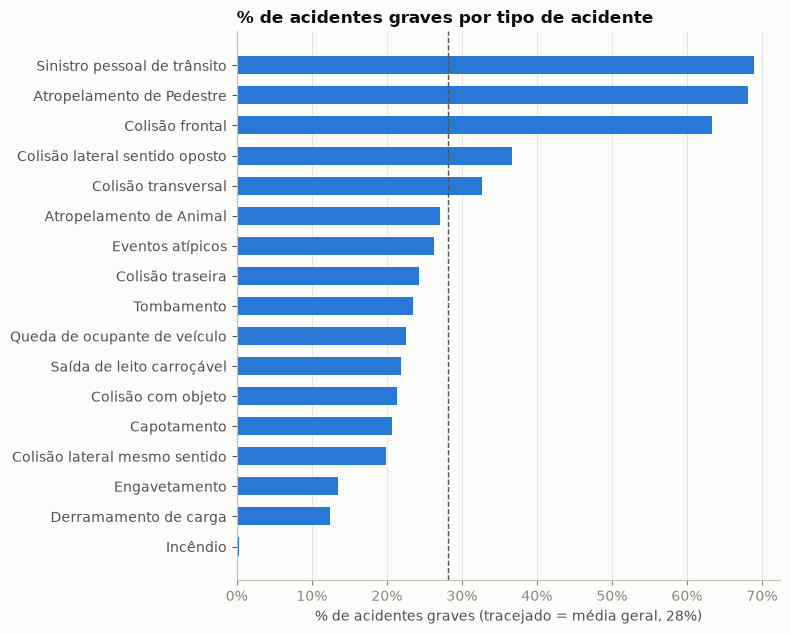

In [5]:
def plot_rate(series: pd.Series, title: str, ax=None):
    # Barra horizontal com a % de graves por categoria e linha da média geral.
    rate = raw.groupby(series)["grave"].mean().sort_values()
    ax = ax or plt.subplots(figsize=(8, 0.32 * len(rate) + 1))[1]
    ax.barh(rate.index, rate.values, color=BLUE, height=0.6)
    overall = raw["grave"].mean()
    ax.axvline(overall, color=INK_2, linestyle="--", linewidth=1)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(f"% de acidentes graves (tracejado = média geral, {overall:.0%})")
    return ax

plot_rate(raw["tipo_acidente"], "% de acidentes graves por tipo de acidente")
plt.tight_layout()

O **tipo de acidente** separa muito bem a gravidade. Atropelamentos e colisões frontais passam de 60% de graves, mais que o dobro da média. Já colisões laterais no mesmo sentido, engavetamentos e derramamentos de carga ficam bem abaixo. Esse é o sinal mais forte disponível na ligação para o 191.

### 3.2 Horário e veículos envolvidos

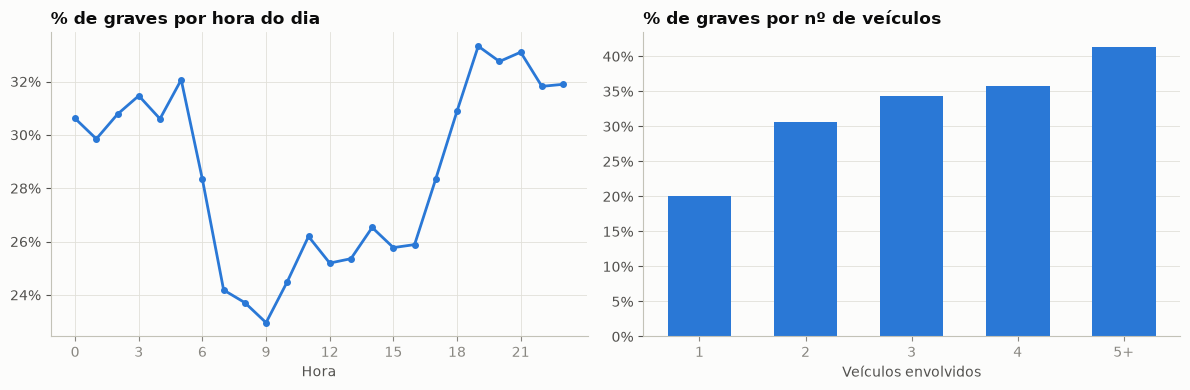

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

by_hour = raw.groupby(raw["horario"].str[:2].astype(int))["grave"].mean()
ax1.plot(by_hour.index, by_hour.values, color=BLUE, linewidth=2, marker="o", markersize=4)
ax1.set_title("% de graves por hora do dia")
ax1.set_xlabel("Hora")
ax1.set_xticks(range(0, 24, 3))

by_veic = raw.groupby(raw["veiculos"].clip(upper=5))["grave"].mean()
labels = [str(v) if v < 5 else "5+" for v in by_veic.index]
ax2.bar(labels, by_veic.values, color=BLUE, width=0.6)
ax2.set_title("% de graves por nº de veículos")
ax2.set_xlabel("Veículos envolvidos")
ax2.grid(axis="x", visible=False)

for ax in (ax1, ax2):
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
plt.tight_layout()

- **Noite e madrugada** (das 18h às 5h) têm cerca de 30–33% de graves, contra cerca de 23–26% durante o dia. Os fatores prováveis são visibilidade menor, velocidades maiores com menos tráfego, cansaço e álcool.
- **Quanto mais veículos envolvidos, maior a proporção de graves**: de 20% com 1 veículo para mais de 40% com 5 ou mais. Mais veículos significam mais pessoas expostas, e basta uma ferida gravemente para o acidente ser classificado como grave.

### 3.3 Contexto da via

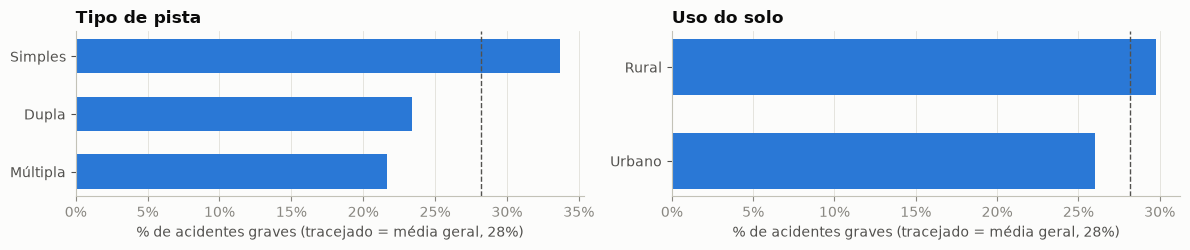

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 2.6))
plot_rate(raw["tipo_pista"], "Tipo de pista", ax=axes[0])
plot_rate(raw["uso_solo"].map({"Sim": "Urbano", "Não": "Rural"}), "Uso do solo", ax=axes[1])
plt.tight_layout()

**Pista simples** e **área rural** têm mais acidentes graves. Na pista simples há risco de colisão frontal, e na área rural as velocidades são maiores.

## 4. Modelo de triagem (principal)

**Divisão temporal:** treinamos com **2024 + 2025** e testamos em **2026**. Uma divisão aleatória misturaria passado e futuro. A divisão por ano simula o uso real: o modelo é treinado com o histórico e aplicado em ocorrências novas.

**Features da triagem** (o que se sabe na ligação para o 191):

In [8]:
train_mask, test_mask = raw["ano"].isin(TRAIN_YEARS), raw["ano"].isin(TEST_YEARS)
X_train, y_train = build_features(raw[train_mask]), raw.loc[train_mask, "grave"]
X_test, y_test = build_features(raw[test_mask]), raw.loc[test_mask, "grave"]
print(f"Treino {TRAIN_YEARS}: {len(X_train):,} | Teste {TEST_YEARS}: {len(X_test):,}")
print("Categóricas:", TRIAGE.categorical)
print("Numéricas:  ", TRIAGE.numeric)
print("Binárias:   ", TRIAGE.binary)
print("Target enc.:", TRIAGE.target_encoded)

Treino [2024, 2025]: 145,731 | Teste [2026]: 48,712
Categóricas: ['uf', 'br', 'dia_semana', 'hora', 'mes', 'fase_dia', 'sentido_via', 'condicao_metereologica', 'tipo_pista', 'uso_solo', 'tipo_acidente']
Numéricas:   ['km', 'latitude', 'longitude', 'veiculos', 'pessoas']
Binárias:    ['tracado_Reta', 'tracado_Curva', 'tracado_Declive', 'tracado_Aclive', 'tracado_Interseção de Vias', 'tracado_Rotatória', 'tracado_Retorno Regulamentado', 'tracado_Em Obras', 'tracado_Viaduto', 'tracado_Ponte', 'tracado_Desvio Temporário', 'tracado_Túnel']
Target enc.: ['municipio', 'trecho']


O **pipeline** junta pré-processamento e modelo em um único objeto:
- **OneHotEncoder** transforma categorias em colunas 0/1 e agrupa categorias raras (menos de 50 casos).
- **StandardScaler** coloca as variáveis numéricas na mesma escala.
- **TargetEncoder** troca município e trecho da rodovia (milhares de categorias) pela taxa histórica de graves de cada um. Detalhes na seção 4.2.
- **Regressão Logística** com `class_weight="balanced"` compensa o desbalanceamento das classes.

Como o pré-processamento é ajustado (*fit*) **só no treino**, nenhuma informação do teste vaza para o modelo.

In [9]:
dummy = make_pipeline(TRIAGE, DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
triage_model = make_pipeline(TRIAGE, make_logistic_regression()).fit(X_train, y_train)

results = pd.DataFrame({
    "Dummy (sempre 'leve')": evaluate(dummy, X_test, y_test),
    "Triagem — Logistic Regression": evaluate(triage_model, X_test, y_test),
}).T
results

,Acurácia,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy (sempre 'leve'),0.720,0.000,0.000,0.000,0.500,0.280
Triagem — Logistic Regression,0.687,0.454,0.580,0.510,0.715,0.524


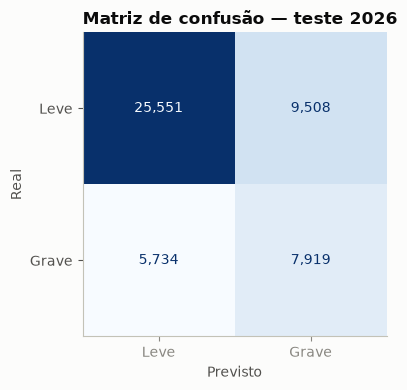

In [10]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_estimator(
    triage_model, X_test, y_test, display_labels=["Leve", "Grave"],
    cmap="Blues", colorbar=False, values_format=",", ax=ax)
ax.grid(False)
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusão — teste 2026")
plt.tight_layout()

**Como ler os resultados:**
- O **Dummy** tem acurácia de 72% e não encontra nenhum acidente grave. Ele é a régua mínima.
- A Regressão Logística encontra **cerca de 58% dos acidentes graves** (recall). Quando ela indica "grave", acerta cerca de 45% das vezes (precision).
- **ROC-AUC ≈ 0.72**: escolhendo ao acaso um acidente grave e um leve, o modelo dá a maior probabilidade ao grave em cerca de 72% dos casos (0.5 seria chute).

Em triagem, **errar por excesso** (mandar resgate avançado sem necessidade) costuma custar menos do que **errar por falta**. Por isso o limiar de decisão (hoje 0.5) deve ser ajustado para priorizar o recall. Isso é feito na seção 4.3.

### 4.1 Comparando algoritmos: Random Forest e XGBoost

A Regressão Logística é **linear**: soma o efeito de cada feature de forma independente. Modelos baseados em **árvores** conseguem capturar **interações** como "colisão frontal **e** pista simples **e** noite". Testamos dois, com o mesmo pipeline e o mesmo split temporal:
- **Random Forest:** várias árvores independentes que votam juntas.
- **XGBoost:** árvores em sequência, cada uma corrigindo o erro das anteriores (*gradient boosting*).

In [11]:
from train import make_random_forest, make_xgboost

rf_model = make_pipeline(TRIAGE, make_random_forest()).fit(X_train, y_train)
xgb_model = make_pipeline(TRIAGE, make_xgboost(y_train)).fit(X_train, y_train)

models = {
    "Logistic Regression": triage_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
}
pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T

,Acurácia,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.687,0.454,0.580,0.510,0.715,0.524
Random Forest,0.728,0.515,0.473,0.493,0.717,0.530
XGBoost,0.686,0.454,0.592,0.514,0.721,0.539


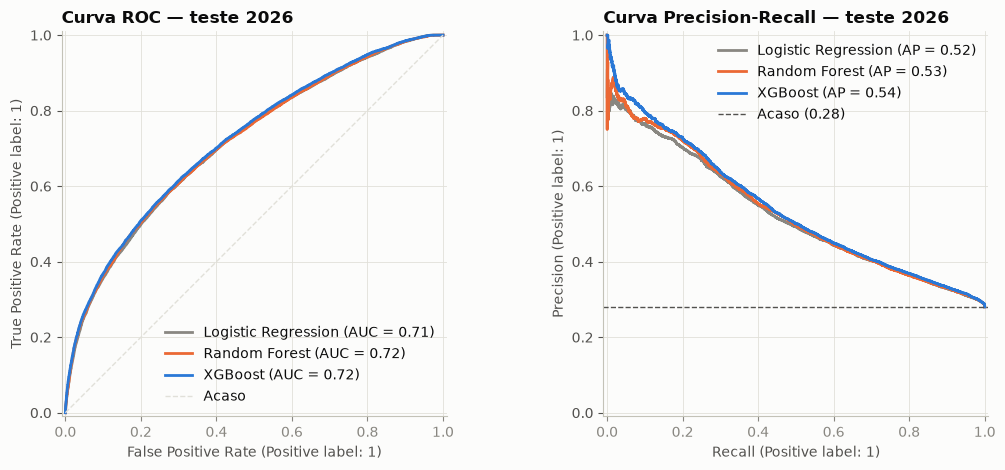

In [12]:
from sklearn.metrics import PrecisionRecallDisplay

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))
colors = {"Logistic Regression": MUTED, "Random Forest": ORANGE, "XGBoost": BLUE}
for name, m in models.items():
    kw = {"color": colors[name], "linewidth": 2}
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, curve_kwargs=kw, ax=ax1)
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, curve_kwargs=kw, ax=ax2)
ax1.plot([0, 1], [0, 1], color=GRID, linestyle="--", linewidth=1, label="Acaso")
ax2.axhline(y_test.mean(), color=INK_2, linestyle="--", linewidth=1,
            label=f"Acaso ({y_test.mean():.2f})")
ax1.set_title("Curva ROC — teste 2026")
ax2.set_title("Curva Precision-Recall — teste 2026")
ax1.legend(loc="lower right")
ax2.legend(loc="upper right")
plt.tight_layout()

**Leitura:**
- Os três modelos ficam **muito próximos**: o XGBoost lidera por pouco (ROC-AUC ≈ 0.72, PR-AUC ≈ 0.54), contra 0.72 e 0.52 da Regressão Logística. As curvas quase se sobrepõem.
- Se modelos não lineares quase não melhoram, o **limite está nas features, não no algoritmo**: com o que se sabe na ligação, o sinal disponível acaba perto de 0.72.
- Com o limiar padrão de 0.5, cada modelo escolhe um ponto de operação diferente (o Random Forest erra menos no total, mas deixa passar mais graves; o XGBoost tem o maior recall). As métricas que não dependem do limiar (AUCs, curvas) são a base justa para comparar. A escolha do ponto de operação é feita na seção 4.3.

### 4.2 Quanto as features geográficas acrescentam?

O modelo usa três informações de localização além de UF, BR e km:
- **Latitude e longitude**, como numéricas. Árvores conseguem recortar regiões do mapa com elas.
- **Município** e **trecho** (BR + UF + faixa de 10 km, ex.: `116_SP_23` = BR-116 em SP, km 230 a 239). Juntas, essas colunas têm milhares de categorias, e o one-hot geraria milhares de colunas quase vazias. Por isso usamos ***target encoding***: cada categoria vira a **taxa histórica de acidentes graves** nela.

O target encoding tem uma armadilha: a taxa de um trecho inclui o próprio acidente que estamos prevendo, e isso é *leakage*. O `TargetEncoder` do scikit-learn resolve com ***cross-fitting***: no treino, cada linha é codificada com taxas calculadas nos outros 4 de 5 *folds*, sem ela. No teste, usa as taxas do treino inteiro. Categorias com poucos acidentes são puxadas para a média geral (*smoothing*), para que um trecho com 2 acidentes, ambos graves, não vire "100% de risco".

Para medir o ganho, comparamos o XGBoost com e sem essas features. Um ganho pequeno pode ser sorte do conjunto de teste, então usamos um ***bootstrap pareado***: sorteamos 300 versões do teste (com reposição), calculamos a diferença de PR-AUC entre os dois modelos **nas mesmas amostras** e olhamos o intervalo que contém 95% das diferenças. Se ele não inclui zero, o ganho não é ruído.

In [13]:
from dataclasses import replace
from sklearn.metrics import average_precision_score

GEO = ["latitude", "longitude"]
no_geo = replace(TRIAGE, numeric=[c for c in TRIAGE.numeric if c not in GEO], target_encoded=[])
xgb_no_geo = make_pipeline(no_geo, make_xgboost(y_train)).fit(X_train, y_train)

proba_geo = xgb_model.predict_proba(X_test)[:, 1]
proba_no_geo = xgb_no_geo.predict_proba(X_test)[:, 1]

rng = np.random.default_rng(0)
y = y_test.to_numpy()
diffs = []
for _ in range(300):
    i = rng.integers(0, len(y), len(y))
    diffs.append(average_precision_score(y[i], proba_geo[i])
                 - average_precision_score(y[i], proba_no_geo[i]))
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"Ganho de PR-AUC com features geográficas: {np.mean(diffs):+.4f} "
      f"(IC 95%: {low:+.4f} a {high:+.4f})")

pd.DataFrame({
    "XGBoost sem features geográficas": evaluate(xgb_no_geo, X_test, y_test),
    "XGBoost com features geográficas": evaluate(xgb_model, X_test, y_test),
}).T[["ROC-AUC", "PR-AUC"]]

Ganho de PR-AUC com features geográficas: +0.0054 (IC 95%: +0.0032 a +0.0075)


,ROC-AUC,PR-AUC
XGBoost sem features geográficas,0.718,0.534
XGBoost com features geográficas,0.721,0.539


**Leitura:** o ganho é **real** (o intervalo não inclui zero), mas **pequeno**, cerca de +0.005 de PR-AUC. Também testamos trechos de 1 e 5 km, o volume histórico de acidentes do trecho e a delegacia da PRF: todas as variantes ficaram dentro do ruído umas das outras, então ficou a versão mais simples.

O local ajuda pouco porque, na triagem, o **tipo de acidente** já carrega a maior parte do sinal. E a maioria dos trechos tem poucos acidentes, então o *smoothing* puxa suas taxas para perto da média.

### 4.3 Ajuste do limiar de decisão

O modelo devolve uma **probabilidade**. O **limiar** decide a partir de qual valor o acidente é tratado como grave e recebe resgate avançado. O padrão 0.5 é arbitrário. Como deixar de enviar resgate a um acidente grave (**falso negativo**) custa mais caro que um envio desnecessário (**falso positivo**), escolhemos o limiar que garante **recall de pelo menos 80%**.

O limiar também é aprendido com dados, então **não pode ser escolhido olhando o teste**: se fosse, o recall de 2026 seria otimista, porque o teste teria virado parte do treino. Fazemos uma validação temporal **dentro do treino**: o modelo treina em 2024 e o limiar é escolhido em 2025, como o **maior** limiar que ainda dá recall ≥ 80% (quanto maior o limiar, menos alarmes falsos). O limiar é então aplicado ao modelo treinado em 2024 + 2025 e avaliado em 2026.

In [14]:
from threshold import FIT_YEARS, TARGET_RECALL, VALID_YEARS, metrics_at, threshold_for_recall

fit_mask, valid_mask = raw["ano"].isin(FIT_YEARS), raw["ano"].isin(VALID_YEARS)
y_fit, y_valid = raw.loc[fit_mask, "grave"], raw.loc[valid_mask, "grave"]
xgb_fit = make_pipeline(TRIAGE, make_xgboost(y_fit)).fit(build_features(raw[fit_mask]), y_fit)
proba_valid = xgb_fit.predict_proba(build_features(raw[valid_mask]))[:, 1]
threshold = threshold_for_recall(y_valid, proba_valid, TARGET_RECALL)
print(f"Limiar escolhido em {VALID_YEARS} (recall >= {TARGET_RECALL:.0%}): {threshold:.3f}")

pd.DataFrame({
    "Limiar padrão": metrics_at(y_test, proba_geo, 0.5),
    "Limiar ajustado": metrics_at(y_test, proba_geo, threshold),
}).T

Limiar escolhido em [2025] (recall >= 80%): 0.389


,Limiar,Recall,Precision,Taxa de acionamento
Limiar padrão,0.500,0.592,0.454,0.365
Limiar ajustado,0.389,0.825,0.360,0.642


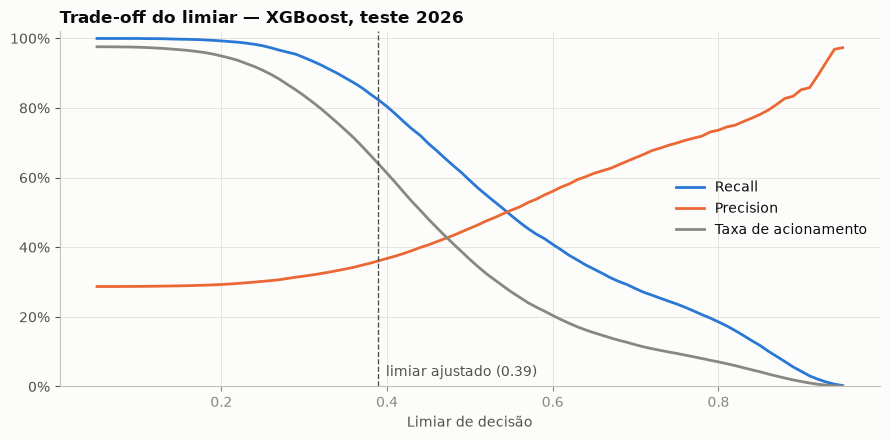

In [15]:
grid = pd.DataFrame([metrics_at(y_test, proba_geo, t) for t in np.arange(0.05, 0.951, 0.01)])

fig, ax = plt.subplots(figsize=(9, 4.5))
for col, color in [("Recall", BLUE), ("Precision", ORANGE), ("Taxa de acionamento", MUTED)]:
    ax.plot(grid["Limiar"], grid[col], color=color, linewidth=2, label=col)
ax.axvline(threshold, color=INK_2, linestyle="--", linewidth=1)
ax.text(threshold + 0.01, 0.03, f"limiar ajustado ({threshold:.2f})", color=INK_2)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Limiar de decisão")
ax.set_title("Trade-off do limiar — XGBoost, teste 2026")
ax.legend(loc="center right")
plt.tight_layout()

**Leitura:**
- O limiar escolhido em 2025 deu **recall de cerca de 82% em 2026**, acima da meta. Isso mostra que ele se manteve de um ano para o outro.
- O preço aparece na **taxa de acionamento**: para pegar 4 de cada 5 acidentes graves, o resgate avançado seria acionado em **cerca de 64% das ligações**, contra 36% com o limiar 0.5.
- A **precision** cai para cerca de 36%: só 1 em cada 3 acionamentos é de fato grave. Se o resgate fosse enviado a todas as ligações, a taxa de acerto seria de 28%, então o modelo melhora pouco esse número.
- O gráfico mostra o trade-off completo: subir o limiar reduz os acionamentos e aumenta a precision, mas deixa passar mais graves. A escolha do ponto é uma **decisão operacional** (quanto resgate avançado existe, qual o custo de um atraso), não estatística. O modelo só mostra o preço de cada opção.

Mudar o limiar **não melhora o modelo**, só escolhe em que ponto do trade-off ficar. Para melhorar o ponto de operação, é preciso mais informação discriminativa.

## 5. Interpretação do modelo

Na Regressão Logística, cada coeficiente mostra se a feature **aumenta** (positivo) ou **diminui** (negativo) a chance de o acidente ser grave. O gráfico abaixo mostra os 20 coeficientes de maior magnitude.

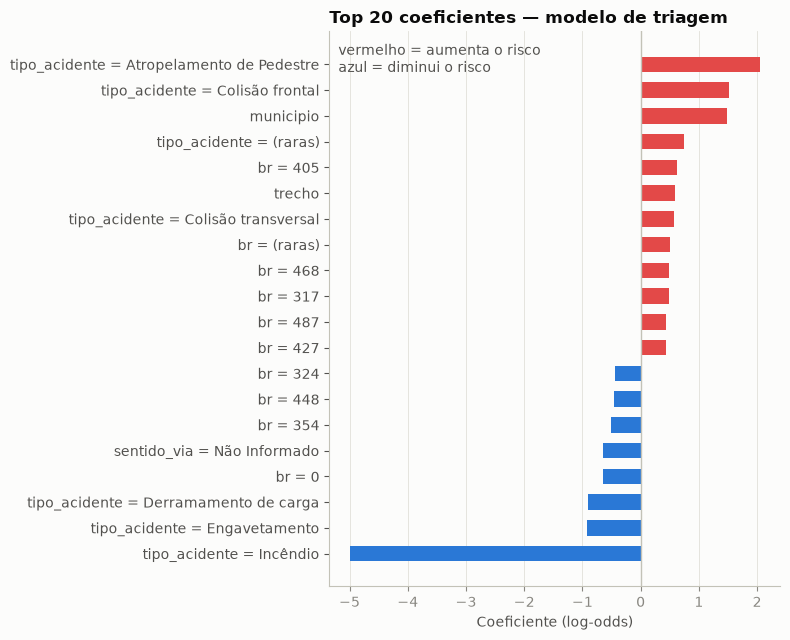

In [16]:
names = triage_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(triage_model.named_steps["model"].coef_[0], index=names)
def pretty(name: str) -> str:
    # "cat__tipo_acidente_Colisão frontal" -> "tipo_acidente = Colisão frontal"
    name = name.split("__", 1)[1].replace("infrequent_sklearn", "(raras)")
    for col in TRIAGE.categorical:
        if name.startswith(col + "_"):
            return f"{col} = {name[len(col) + 1:]}"
    return name

coefs.index = coefs.index.map(pretty)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index[:20]).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.index, top.values, color=np.where(top > 0, RED, BLUE), height=0.6)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_title("Top 20 coeficientes — modelo de triagem")
ax.set_xlabel("Coeficiente (log-odds)")
ax.text(0.02, 0.98, "vermelho = aumenta o risco\nazul = diminui o risco",
        transform=ax.transAxes, ha="left", va="top", color=INK_2)
plt.tight_layout()

**Leitura dos coeficientes:**
- **Tipo de acidente domina.** *Atropelamento de pedestre* e *colisão frontal* são os maiores aumentos de risco, o que confirma a EDA.
- *Incêndio* tem um coeficiente muito negativo porque quase nunca resulta em vítimas graves nesta base (e tem poucos casos).
- Várias **BRs** aparecem no topo. Isso indica diferenças regionais (tipo de rodovia, volume de tráfego, distância de hospitais), mas são categorias com menos dados e coeficientes mais instáveis. Merecem um olhar com cuidado antes de qualquer conclusão.
- **`municipio` e `trecho`** aparecem com coeficientes altos, mas a escala deles é diferente. Eles são a taxa histórica de graves (target encoding), entre 0 e 1, sem padronização, então o coeficiente mede o efeito de ir de 0% a 100% de graves. Na prática as taxas variam numa faixa bem menor, e o efeito real é modesto, como mostrou a seção 4.2. O sinal positivo faz sentido: locais com histórico de mais graves tendem a ter acidentes mais graves.

> Os coeficientes mostram **associação**, não **causalidade**: indicam o que o modelo aprendeu a usar para prever, não necessariamente o que causa a gravidade.

## 6. Experimento: Avaliando o Modelo Apenas com Variáveis Pré-Evento (Abordagem Preventiva)

**Pergunta:** e se quiséssemos prever a gravidade **antes** do acidente, para planejar o patrulhamento preventivo? Nesse cenário não sabemos o tipo de acidente nem quantos veículos e pessoas estarão envolvidos. Sobra apenas o **contexto**: local (UF, BR, km, município, coordenadas e histórico do trecho), tempo (hora, dia, mês, fase do dia), clima e características da via.

Treinamos **o mesmo pipeline e o mesmo algoritmo**, mudando apenas o conjunto de features:

In [17]:
print("Features removidas em relação à triagem:",
      sorted(set(TRIAGE.columns) - set(PREVENTIVE.columns)))

preventive_model = make_pipeline(PREVENTIVE, make_logistic_regression()).fit(X_train, y_train)

comparison = pd.DataFrame({
    "Triagem (contexto + relato do 191)": evaluate(triage_model, X_test, y_test),
    "Preventivo (só contexto pré-evento)": evaluate(preventive_model, X_test, y_test),
}).T
comparison

Features removidas em relação à triagem: ['pessoas', 'tipo_acidente', 'veiculos']


,Acurácia,Precision,Recall,F1,ROC-AUC,PR-AUC
Triagem (contexto + relato do 191),0.687,0.454,0.580,0.510,0.715,0.524
Preventivo (só contexto pré-evento),0.600,0.365,0.575,0.446,0.633,0.401


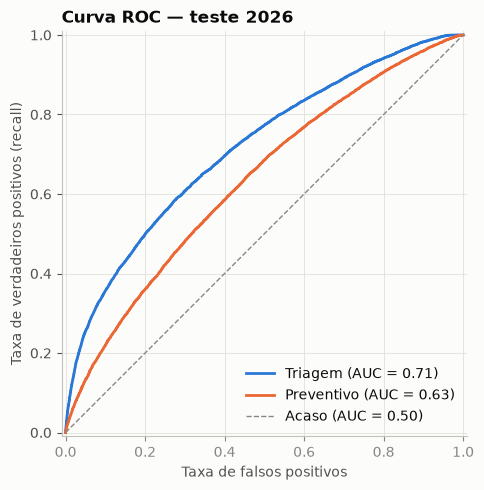

In [18]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for model, label, color in [(triage_model, "Triagem", BLUE),
                            (preventive_model, "Preventivo", ORANGE)]:
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=label,
                                   curve_kwargs={"color": color, "linewidth": 2}, ax=ax)
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Acaso (AUC = 0.50)")
ax.set_title("Curva ROC — teste 2026")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.legend(loc="lower right")
plt.tight_layout()

### Por que o desempenho cai?

O ROC-AUC cai de **≈ 0.72 (triagem)** para **≈ 0.63 (preventivo)**, e o PR-AUC cai de **≈ 0.52** para **≈ 0.40**. Os motivos:

1. **As features mais fortes descrevem a dinâmica do acidente.** Como mostrou a EDA, *tipo de acidente* e *nº de veículos* separam bem a gravidade: um atropelamento é muito mais grave que uma colisão traseira. Essa informação só existe depois que o acidente acontece.
2. **O contexto diz *onde* e *quando* o risco é maior, não *o que* vai acontecer.** Na mesma curva de pista simples, de madrugada e com chuva, acontecem tanto batidas leves quanto colisões frontais fatais. O contexto muda a probabilidade média, mas não separa bem os casos individuais.
3. **A gravidade depende de fatores que não estão na base:** velocidade no impacto, uso de cinto, tipo de veículo (moto x caminhão), tempo até o socorro.

**Conclusão do experimento:** o modelo preventivo ainda é **melhor que o acaso** (AUC 0.63 > 0.50) e pode servir para **ranquear trechos e horários de maior risco** no planejamento do patrulhamento. Porém, ele não serve para prever a gravidade de uma ocorrência específica. Para a decisão de despacho, o modelo de triagem é claramente superior, e por isso é o modelo principal do projeto.

> **Observação sobre `causa_acidente`:** essa coluna também ficou fora da triagem, porque a causa é definida **depois**, na investigação da PRF, e não está disponível na ligação para o 191. A célula abaixo mostra que incluí-la quase não muda o resultado. Mesmo assim, manter fora variáveis que não existiriam no momento da previsão é o que garante que o modelo funcione em produção.

In [19]:
with_cause = replace(TRIAGE, categorical=TRIAGE.categorical + ["causa_acidente"])
cause_model = make_pipeline(with_cause, make_logistic_regression()).fit(X_train, y_train)
pd.DataFrame({
    "Triagem": evaluate(triage_model, X_test, y_test),
    "Triagem + causa_acidente (indisponível no 191)": evaluate(cause_model, X_test, y_test),
}).T[["ROC-AUC", "PR-AUC", "Recall"]]

,ROC-AUC,PR-AUC,Recall
Triagem,0.715,0.524,0.580
Triagem + causa_acidente (indisponível no 191),0.722,0.534,0.597


## 7. Conclusões e próximos passos

- O **modelo de triagem** supera com folga o baseline. Entre os algoritmos testados, o **XGBoost** é o melhor por pouco (ROC-AUC 0.72 / PR-AUC 0.54), mas a diferença para a Regressão Logística (0.72 / 0.52) é pequena. O gargalo são as features.
- As **features geográficas** (coordenadas e histórico de município e trecho) trazem um ganho real, mas pequeno (+0.005 de PR-AUC).
- Com o **limiar ajustado** para recall de 80%, o modelo pega cerca de 82% dos graves em 2026, mas aciona resgate avançado em cerca de 64% das ligações.
- O **experimento preventivo** confirma que a maior parte do sinal vem do relato da ocorrência, não do contexto.

**Próximos passos:**
1. Features sobre os **veículos e pessoas envolvidos** (ex.: motocicleta, pedestre), a partir dos dados da PRF por pessoa e por veículo, como aproximação do que o atendente do 191 pode perguntar na ligação.